# SAEFS — external validation on CPTAC-CCRCC

Reproduces the **TCGA-KIRC → CPTAC-CCRCC** setting of

> *Semantic-Anchored Evidential Fusion for Domain-Robust Whole-Slide Survival Analysis*

The model is trained on TCGA-KIRC and evaluated **without any adaptation or
fine-tuning** on the CPTAC-CCRCC cohort — a different set of hospitals, scanners
and staining protocols, which is what makes this a domain-robustness test rather
than a within-cohort cross-validation.

The notebook reproduces the reported C-index from the released weights and then
runs, on that same model, the analyses the evidential formulation makes possible:
risk-group stratification, calibration of the predicted survival curves,
uncertainty-based selective prediction, and a leave-one-anchor-out ranking of the
semantic anchors. It evaluates; it does not train. `scripts/train.py` is the
entry point for training on your own cohort.

### What you need

| input | what it is |
|---|---|
| **patch features** | one `<slide_id>.pt` per slide, an `(n_patches, 512)` array of CONCH patch embeddings (20×, 256 px) |
| **released weights** | `checkpoints/saefs_kirc.pt`, shipped with this repository |
| **split CSVs** | `train_tcga.csv` and `test_cptackirc_unfold.csv`: `case_id, slide_id, dss_survival_days, dss_censorship` |
| **semantic anchors** | `wsi_questions_wide.csv` (`slide_id, Q1..Q12`) and its CONCH text embeddings `text_embs_conch.npy` |

No dataset is bundled with this repository. `docs/data_preparation.md` gives the
exact file contract, and `scripts/encode_text.py` builds the anchor embeddings
from your own VQA answers.

**Runtime.** A few minutes, almost all of it reading the patch features off disk
once (`cache_features=True`); the evaluation itself is a single pass over 180
cases.

## 0 · Configuration

Everything machine-specific lives in this one cell.

In [1]:
import os
import sys
from pathlib import Path

# repository root: the nearest ancestor that contains the saefs package
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "saefs" / "__init__.py").exists())
sys.path.insert(0, str(REPO_ROOT))

# Root that the four paths below are resolved against. Override without editing
# the notebook:  SAEFS_DATA_ROOT=/my/data jupyter lab
DATA_ROOT = Path(os.environ.get("SAEFS_DATA_ROOT", "/hpc/home/e0950223"))

# 1. directory (or directories) holding one <slide_id>.pt per slide
FEAT_DIRS = [
    DATA_ROOT / "MMP/VLSA-Datasets/tcga_cptac_ccrcc/feats-CONCH-vl-proj"
                "/extracted_mag20x_patch256_fp/feats_pt",
]
# 2. directory holding the split CSVs and the anchor embeddings
SPLIT_DIR = DATA_ROOT / "MyProject/splits/survival/TCGA_KIRC_overall_survival_k=0"
TRAIN_SPLIT = "train_tcga.csv"
TEST_SPLIT = "test_cptackirc_unfold.csv"
# 3. the wide VQA answer table and its CONCH embeddings
ANCHOR_CSV = DATA_ROOT / "MyProject/data/captions/KIRC/wsi_questions_wide.csv"
ANCHOR_EMB = SPLIT_DIR / "text_embs_conch.npy"

# where this notebook writes checkpoints / predictions / figures
RESULTS_DIR = REPO_ROOT / "results" / "kirc_reproduction"
FIG_DIR = RESULTS_DIR / "figures"

# ---------------------------------------------------------------------------
# Reported result for this row of the paper, used as the reproduction target.
# ---------------------------------------------------------------------------
REPORTED = {"c_index": 0.677}   # reported for TCGA-KIRC -> CPTAC-CCRCC
REPORTED_SETTING = "alpha = 0.5, r = 1.0, tau = 1.0, lr = 1e-4, 30 epochs, AdamW, wd 1e-5, cosine, no warmup"

# the released weights behind the reported number
CKPT = REPO_ROOT / "checkpoints" / "saefs_kirc.pt"

for p in [*FEAT_DIRS, SPLIT_DIR, ANCHOR_CSV, ANCHOR_EMB, CKPT,
          SPLIT_DIR / TRAIN_SPLIT, SPLIT_DIR / TEST_SPLIT]:
    assert Path(p).exists(), f"missing: {p}"
print("all inputs found")

all inputs found


In [2]:
import time
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from saefs import SAEFS, SAEFSConfig, build_datasets, evaluate, load_pretrained
from saefs.losses import EvidentialSurvLoss
from saefs.engine import build_time_grid, c_index
from saefs.viz import (SERIES, SEQ_BLUE, DIVERGING, SURFACE, INK, INK_2, MUTED,
                       BASELINE, set_style, style_axes, direct_label, km_curves, risk_groups)

set_style()
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=200)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"torch {torch.__version__} on {DEVICE}")
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(0))

torch 2.8.0+cu128 on cuda


NVIDIA H200 NVL


## 1 · The two cohorts

One config object names the data, the model and the optimisation; it is the
setting the reported number was produced with. Building the datasets reads every
bag once and caches it, which is the slow step — everything after it is fast.

`alpha` and `r` are the two hyper-parameters that define the fusion; they are
explained with the model in the next section.

In [3]:
cfg = SAEFSConfig(
    feat_dirs=[str(p) for p in FEAT_DIRS],
    split_dir=str(SPLIT_DIR),
    train_split=TRAIN_SPLIT,
    test_split=TEST_SPLIT,
    anchor_csv=str(ANCHOR_CSV),
    anchor_emb=str(ANCHOR_EMB),
    target_col="dss_survival_days",     # disease-specific survival
    n_label_bins=4,
    num_questions=12,
    # --- model ---
    alpha=0.5, r=1.0, tau=1.0, fusion="cautious",
    # --- optimisation ---
    lr=2e-4, wd=1e-5, lr_scheduler="cosine", max_epochs=30, seed=1,
    annealing_step=10500,               # the KL ramp the reported run used
    # --- runtime ---
    cache_features=True,                # read the 8 GB of features once
    cache_device=DEVICE,                # keep them on the GPU if it has room
    results_dir=str(RESULTS_DIR),
)

t0 = time.time()
datasets, loaders = build_datasets(cfg)
print(f"\nloaded in {time.time() - t0:.0f} s")

train split: train_tcga.csv


  cached 340 bags on cuda (3.43 GB)
  n = 340 cases
test split: test_cptackirc_unfold.csv


  cached 180 bags on cuda (0.82 GB)
  n = 180 cases

loaded in 12 s


In [4]:
def cohort_summary(ds, name):
    t, c = ds.survival_time.numpy(), ds.censorship.numpy()
    bags = ds.bag_sizes()
    return {
        "cohort": name,
        "cases": len(ds),
        "slides": len(ds.data_df),
        "events": int((1 - c).sum()),
        "event rate": f"{(1 - c).mean():.1%}",
        "median follow-up (months)": round(float(np.median(t)) / 30.44, 1),
        "median patches / case": int(np.median(bags)),
    }

summary = pd.DataFrame([
    cohort_summary(datasets["train"], "TCGA-KIRC (train)"),
    cohort_summary(datasets["test"], "CPTAC-CCRCC (external test)"),
]).set_index("cohort")
display(summary)

n_ev = int((1 - datasets["test"].censorship.numpy()).sum())
print(f"\nEvery external number in this notebook rests on {n_ev} observed events. "
      f"A C-index estimated from {n_ev} events carries a standard error of roughly "
      f"+/-{0.3 / n_ev ** 0.5:.2f}, which is the scale to keep in mind when reading "
      f"any difference below.")

,cases,slides,events,event rate,median follow-up (months),median patches / case
cohort,,,,,,
TCGA-KIRC (train),340,346,58,17.1%,37.2,4795
CPTAC-CCRCC (external test),180,339,15,8.3%,29.4,1395



Every external number in this notebook rests on 15 observed events. A C-index estimated from 15 events carries a standard error of roughly +/-0.08, which is the scale to keep in mind when reading any difference below.


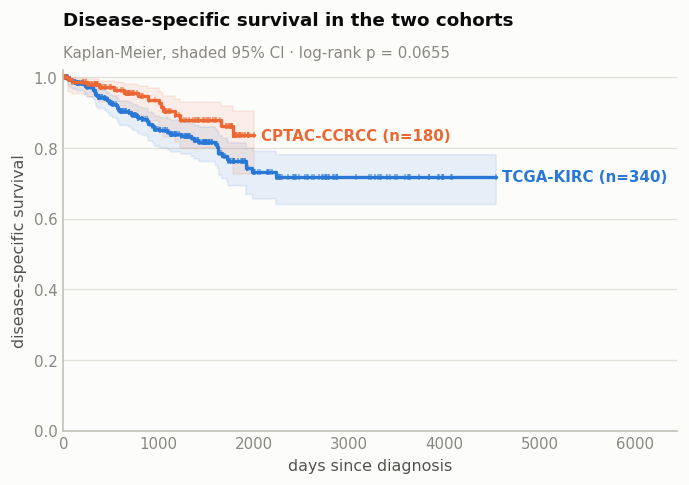

In [5]:
tr, te = datasets["train"], datasets["test"]
dur = np.concatenate([tr.survival_time.numpy(), te.survival_time.numpy()])
evt = np.concatenate([1 - tr.censorship.numpy(), 1 - te.censorship.numpy()])
coh = np.array([0] * len(tr) + [1] * len(te))

fig, ax = plt.subplots(figsize=(6.6, 3.9))
p = km_curves(ax, dur, evt, coh,
              labels=["TCGA-KIRC", "CPTAC-CCRCC"],
              colors=[SERIES[0], SERIES[1]])
ax.set_xlim(0, dur.max() * 1.42)
style_axes(ax, "Disease-specific survival in the two cohorts",
           "days since diagnosis", "disease-specific survival",
           subtitle=f"Kaplan-Meier, shaded 95% CI · log-rank p = {p:.3g}")
save(fig, "01_cohorts"); plt.show()

## 2 · The model

Three evidence sources are computed from the same bag of patches and then
combined at the level of belief masses rather than logits:

| branch | how the slide is summarised | evidence |
|---|---|---|
| **WSI-only** | ABMIL attention pooling over patches | `e_wsi` |
| **Text-guided WSI** | each of the `Q` anchors softly selects the patches it matches, averaged over anchors | `e_tg` |
| **Text-only** | mean of the anchor embeddings | `e_text` |

Each evidence vector defines a Dirichlet `alpha = e + 1`, which maps to a
Bayesian belief assignment `(b, u)` where `u` is the mass left on "don't know".
The pathology and (discounted) text assignments are fused with the **cautious
rule**, which is idempotent and therefore does not double-count the evidence the
two views share — the ordinary Dempster rule would.

The two hyper-parameters:

* **`alpha`** — how much of the pathology evidence comes from the anchor-guided
  branch rather than from plain attention pooling:
  `e_path = (1 - alpha) · e_wsi + alpha · e_tg`. `alpha = 0` is plain ABMIL,
  `alpha = 1` is purely anchor-driven. The main configuration uses **0.5**, so
  both views contribute.
* **`r`** — the reliability of the text source, applied to its belief masses
  before fusion: `b_text ← r · b_text`, `u_text ← u_text + (1-r)(1-u_text)`.
  `r = 1` applies no discounting; smaller values move mass onto "don't know",
  and `r = 0` makes the source vacuous so it abstains. The main configuration
  uses **1.0**.

The endpoints switch branches off algebraically rather than by training: at
`alpha = 1` the WSI-only branch is multiplied by zero, and at `r = 0` the
cautious rule's `min` always selects the pathology side, so in both cases the
corresponding heads receive no gradient at all. `alpha = 0.5, r = 1.0` keeps
all three sources live.

In [6]:
model = SAEFS(emb_dim=cfg.emb_dim, n_classes=cfg.n_label_bins,
              num_questions=cfg.num_questions, alpha=cfg.alpha, r=cfg.r,
              fusion=cfg.fusion)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"\n{n_params:,} trainable parameters\n")

# one forward pass on a synthetic bag, to show what comes out
with torch.no_grad():
    demo = model.forward_no_loss(torch.randn(1, 2000, 512), torch.randn(1, 12, 512))
for k, v in demo.items():
    print(f"  {k:<12} {tuple(v.shape) if torch.is_tensor(v) else v}")

SAEFS(
  (abmil_V): Linear(in_features=512, out_features=512, bias=True)
  (abmil_w): Linear(in_features=512, out_features=1, bias=False)
  (wsi_head): Linear(in_features=512, out_features=4, bias=True)
  (path_head): Linear(in_features=512, out_features=4, bias=True)
  (text_head): Linear(in_features=512, out_features=4, bias=True)
)

269,324 trainable parameters

  evidence     (1, 4)
  A_coattn     (1, 12, 2000)
  A_wsi        (1, 2000, 1)
  u_wsi        (1, 1)
  u_tg         (1, 1)
  u_path       (1, 1)
  u_text       (1, 1)
  u_text_raw   (1, 1)
  u_fused      (1, 1)
  K_conflict   (1, 1)
  K_pre        (1, 1)
  cos_ht       (1, 1)
  r_text       (1, 1)
  alpha_mix    0.5
  e_wsi        (1, 4)
  e_tg         (1, 4)
  e_text       (1, 4)
  e_path       (1, 4)
  b_wsi        (1, 4)
  b_tg         (1, 4)
  b_text       (1, 4)
  b_text_raw   (1, 4)
  b_fused      (1, 4)


## 3 · Reproducing the reported number

The reported C-index is reproduced by **evaluating the released weights**, not by
retraining. That is deliberate: this model's training is not reproducible from a
seed. Two runs of the original research code with an identical configuration
*and an identical seed* produced C-index 0.5523 and 0.6769 on this cohort —
non-deterministic GPU reductions compound over 30 epochs of batch-size-1 training
into different solutions. The seed pins nothing; the weights do.

None of this is mysterious once you look at the cohort: the external C-index is
estimated from 15 observed events among 180 cases, so it is a high-variance
statistic to begin with.

`checkpoints/saefs_kirc.pt` holds the weights behind the reported number. It also
carries two gating MLPs that the original code computed and then overwrote with
the fixed `alpha` / `r`; `load_pretrained` drops them, which is why the
predictions below are unaffected by their absence.

In [7]:
model = load_pretrained(CKPT, emb_dim=cfg.emb_dim, n_classes=cfg.n_label_bins,
                        num_questions=cfg.num_questions, tau=cfg.tau,
                        alpha=cfg.alpha, r=cfg.r, fusion=cfg.fusion).to(DEVICE)

metrics, dumps = evaluate(model, loaders["test"], EvidentialSurvLoss(), DEVICE, dump=True)
print({k: round(v, 4) for k, v in metrics.items()})

{'loss': 11.4546, 'bag_size': 2222.9556, 'c_index': 0.6769, 'c_index_td': 0.6054, 'ibs': 0.2823, 'inbll': 0.7222}


In [8]:
rows = []
for k, reported in REPORTED.items():
    got = metrics.get(k)
    rows.append({"metric": k, "reported": reported, "reproduced": got,
                 "difference": None if got is None else round(got - reported, 4)})
comparison = pd.DataFrame(rows).set_index("metric")
print(f"training setting behind these weights:\n  {REPORTED_SETTING}\n")
display(comparison)

extra = {k: round(v, 4) for k, v in metrics.items()
         if k not in REPORTED and k not in ("loss", "bag_size")}
print("\nother metrics on CPTAC-CCRCC:", extra)

got, want = metrics["c_index"], REPORTED["c_index"]
rel = abs(got - want) / want
print(f"\nagreement: {got:.4f} vs {want:.4f}  ->  {rel:.2%} relative "
      f"({'within' if rel <= 0.01 else 'outside'} the 1% band [{want*0.99:.4f}, {want*1.01:.4f}])")

training setting behind these weights:
  alpha = 0.5, r = 1.0, tau = 1.0, lr = 1e-4, 30 epochs, AdamW, wd 1e-5, cosine, no warmup



,reported,reproduced,difference
metric,,,
c_index,0.677,0.676944,-0.0001



other metrics on CPTAC-CCRCC: {'c_index_td': 0.6054, 'ibs': 0.2823, 'inbll': 0.7222}

agreement: 0.6769 vs 0.6770  ->  0.01% relative (within the 1% band [0.6702, 0.6838])


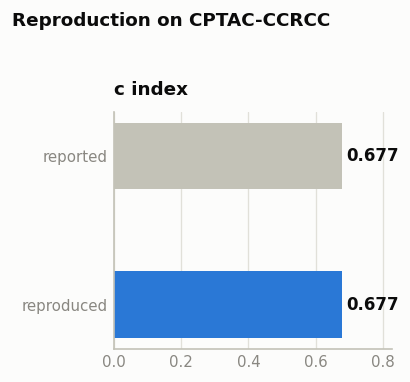

In [9]:
keys = [k for k in REPORTED if metrics.get(k) is not None]
fig, axes = plt.subplots(1, len(keys), figsize=(3.4 * len(keys), 3.2), squeeze=False)
for ax, k in zip(axes[0], keys):
    vals = [REPORTED[k], metrics[k]]
    bars = ax.barh(["reported", "reproduced"], vals,
                   color=[BASELINE, SERIES[0]], height=0.45)
    for bar, v in zip(bars, vals):
        ax.text(v + max(vals) * 0.02, bar.get_y() + bar.get_height() / 2,
                f"{v:.3f}", va="center", fontsize=10, color=INK, fontweight="semibold")
    ax.set_xlim(0, max(vals) * 1.22)
    style_axes(ax, k.replace("_", " "), grid_axis="x")
    ax.invert_yaxis()
fig.suptitle("Reproduction on CPTAC-CCRCC", x=0.02, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
save(fig, "02_reproduction"); plt.show()

## 4 · Risk stratification on the external cohort

A C-index is a ranking statistic; what a clinician reads is whether the predicted
risk actually separates survival curves. Cases are split into equal-sized groups
by the predicted risk score and the groups are compared with a log-rank test.

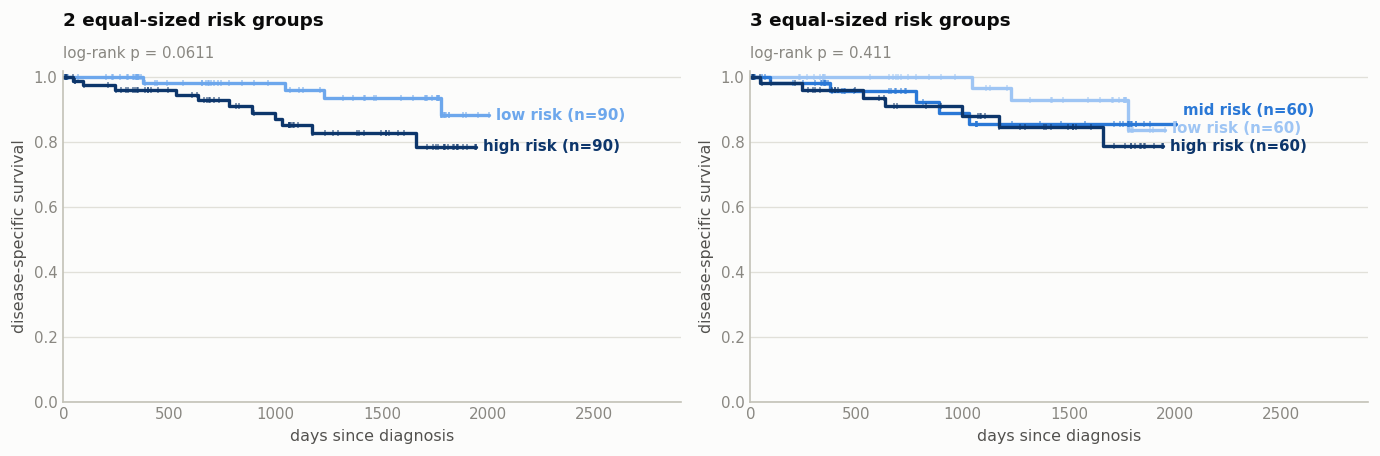

In [10]:
risk, event, time_d = dumps["risk"], 1 - dumps["censorship"], dumps["event_time"]

fig, axes = plt.subplots(1, 2, figsize=(11.6, 3.9))
for ax, n_groups, names, shades in [
    (axes[0], 2, ["low risk", "high risk"], [SEQ_BLUE[2], SEQ_BLUE[7]]),
    (axes[1], 3, ["low risk", "mid risk", "high risk"], [SEQ_BLUE[1], SEQ_BLUE[4], SEQ_BLUE[7]]),
]:
    g = risk_groups(risk, n_groups)
    p = km_curves(ax, time_d, event, g, labels=names, colors=shades, show_ci=False)
    ax.set_xlim(0, time_d.max() * 1.45)
    style_axes(ax, f"{n_groups} equal-sized risk groups", "days since diagnosis",
               "disease-specific survival", subtitle=f"log-rank p = {p:.3g}")
fig.tight_layout()
save(fig, "03_risk_stratification"); plt.show()

## 5 · Calibration of the predicted survival curves

The model does not only rank: the Dirichlet mean over the four discrete bins is a
proper PMF, so it predicts an actual survival curve per case. Comparing the mean
predicted curve of each risk group against that group's Kaplan-Meier estimate
shows whether the predicted *level* is right, not just the ordering.

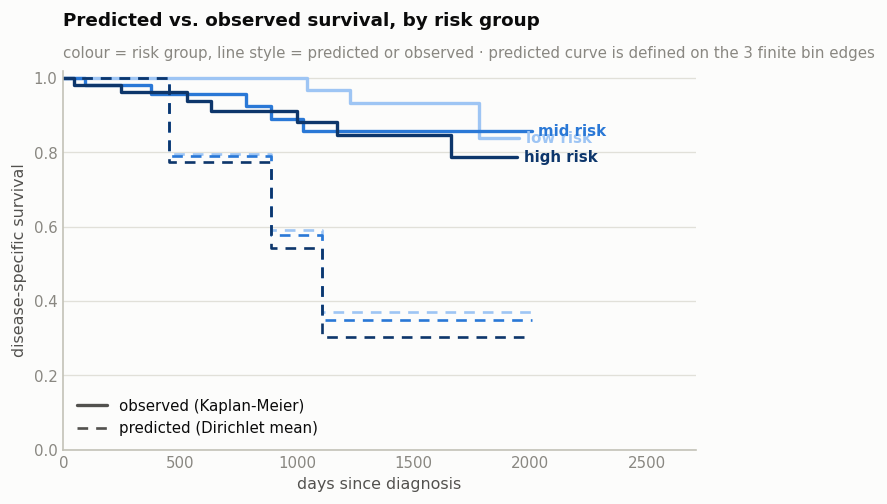

In [11]:
from lifelines import KaplanMeierFitter

grid = build_time_grid(loaders["test"], n_cols=dumps["survival"].shape[1])
g = risk_groups(risk, 3)
names, shades = ["low risk", "mid risk", "high risk"], [SEQ_BLUE[1], SEQ_BLUE[4], SEQ_BLUE[7]]

fig, ax = plt.subplots(figsize=(6.8, 4.1))
for k, (name, color) in enumerate(zip(names, shades)):
    m = g == k
    kmf = KaplanMeierFitter().fit(time_d[m], event[m])
    ax.step(kmf.survival_function_.index, kmf.survival_function_.iloc[:, 0],
            where="post", color=color, linewidth=2.0)
    # the last bin runs to +inf, so its survival column is 0 by construction -- drop it,
    # and carry the last finite value to the right edge so the step has a horizontal run
    s_pred = dumps["survival"][m].mean(axis=0)[:-1]
    ax.step(np.concatenate([[0], grid[:-1], [time_d.max()]]),
            np.concatenate([[1.0], s_pred, s_pred[-1:]]),
            where="post", color=color, linewidth=1.6, linestyle=(0, (4, 3)))
    direct_label(ax, kmf.survival_function_.index.max(),
                 float(kmf.survival_function_.iloc[-1, 0]), name, color)

ax.plot([], [], color=INK_2, linewidth=2.0, label="observed (Kaplan-Meier)")
ax.plot([], [], color=INK_2, linewidth=1.6, linestyle=(0, (4, 3)), label="predicted (Dirichlet mean)")
ax.legend(loc="lower left")
ax.set_xlim(0, time_d.max() * 1.35)
ax.set_ylim(0, 1.02)
style_axes(ax, "Predicted vs. observed survival, by risk group",
           "days since diagnosis", "disease-specific survival",
           subtitle=f"colour = risk group, line style = predicted or observed · predicted curve is defined on the {len(grid) - 1} finite bin edges")
save(fig, "04_calibration"); plt.show()

## 6 · What the evidential layer reports

Every prediction carries the mass `u` that the model left on "don't know", per
branch and after fusion, plus the conflict `K` between the pathology and the text
assignment. These are free by-products of the forward pass.

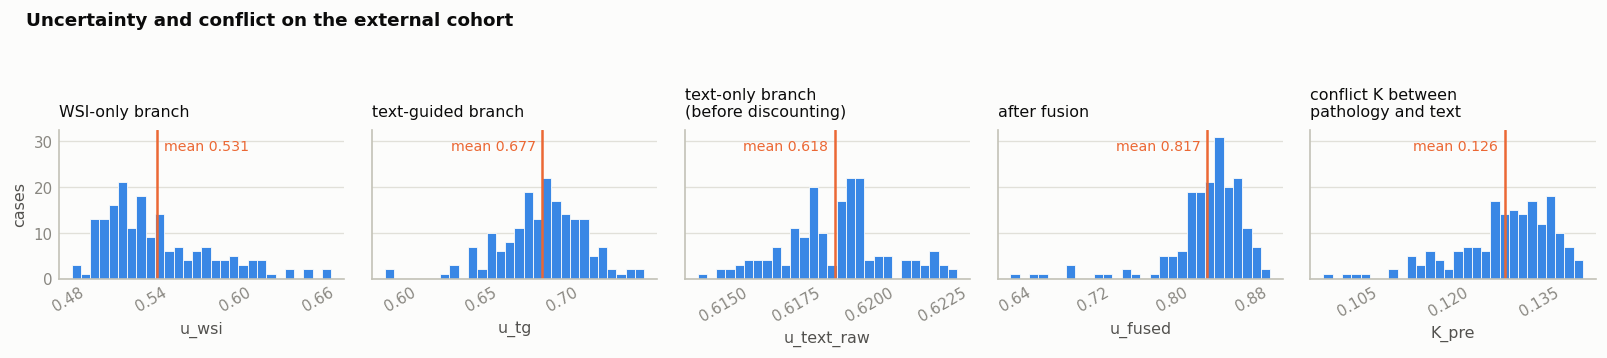

the fusion moved the uncertainty away from the pathology-only value on 100% of cases


In [12]:
panels = [("u_wsi", "\nWSI-only branch"), ("u_tg", "\ntext-guided branch"),
          ("u_text_raw", "text-only branch\n(before discounting)"), ("u_fused", "\nafter fusion"),
          ("K_pre", "conflict K between\npathology and text")]
panels = [(k, t) for k, t in panels if k in dumps]

fig, axes = plt.subplots(1, len(panels), figsize=(2.7 * len(panels), 3.0), sharey=True)
axes = np.atleast_1d(axes)
for i, (ax, (key, title)) in enumerate(zip(axes, panels)):
    v = dumps[key]
    ax.hist(v, bins=28, color=SEQ_BLUE[3], edgecolor=SURFACE, linewidth=0.5)
    ax.axvline(v.mean(), color=SERIES[1], linewidth=1.5)
    # anchor the mean label on whichever side leaves room inside the panel
    left = v.mean() > 0.5 * (v.min() + v.max())
    ax.annotate(f"mean {v.mean():.3g}", xy=(v.mean(), 1), xycoords=("data", "axes fraction"),
                xytext=(-4 if left else 4, -6), textcoords="offset points",
                ha="right" if left else "left", va="top", color=SERIES[1], fontsize=8.5)
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax.ticklabel_format(axis="x", style="plain", useOffset=False)
    ax.tick_params(axis="x", labelrotation=30)
    for lbl in ax.get_xticklabels():
        lbl.set_horizontalalignment("right")
    ax.set_title(title, fontsize=9.5, fontweight="normal", color=INK, pad=8)
    style_axes(ax, "", key, "cases" if i == 0 else "")
fig.suptitle("Uncertainty and conflict on the external cohort",
             x=0.02, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.92))
save(fig, "05_uncertainty"); plt.show()

if np.allclose(dumps["u_fused"], dumps["u_path"], atol=1e-6):
    print("note: the fused mass equals the pathology mass exactly, so the text source "
          "never won the cautious rule's minimum on this cohort — it contributed no "
          "evidence of its own.")
else:
    frac = float(np.mean(~np.isclose(dumps["u_fused"], dumps["u_path"], atol=1e-6)))
    print(f"the fusion moved the uncertainty away from the pathology-only value on "
          f"{frac:.0%} of cases")

## 7 · Is the uncertainty worth anything?

A useful uncertainty must be *selective*: discarding the cases the model is least
sure about should leave a cohort it ranks better. The retention curve below
withholds the most uncertain cases one percentile at a time and recomputes the
C-index; the grey band is what random withholding of the same size achieves.

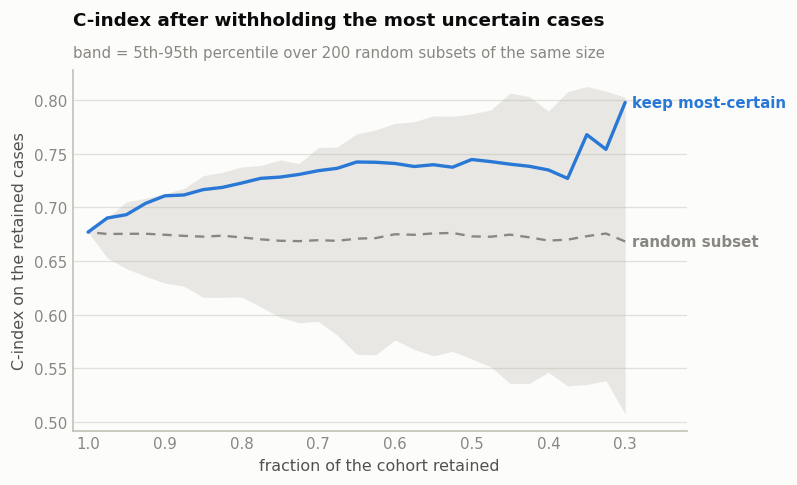

C-index on all 180 cases          : 0.677
C-index on the 50% most certain cases : 0.745

15 of 180 cases had an observed event; the curve stops where fewer than 5 remain.


In [13]:
def retention_curve(score, risk, event, time_d, fractions, min_events=5):
    """C-index on the `f` most confident cases. NaN where the subset is too small
    to support the statistic (a C-index needs comparable pairs, so it is
    undefined once the retained subset has too few observed events)."""
    order = np.argsort(score)                       # most confident first
    out = []
    for f in fractions:
        keep = order[:int(len(risk) * f)]
        if event[keep].sum() < min_events:
            out.append(np.nan)
            continue
        try:
            out.append(c_index(risk[keep], 1 - event[keep], time_d[keep]))
        except (ValueError, ZeroDivisionError):
            out.append(np.nan)
    return np.array(out)

fractions = np.linspace(0.30, 1.0, 29)
u = dumps["u_fused"]
observed = retention_curve(u, risk, event, time_d, fractions)

rng = np.random.default_rng(0)
random_draws = np.stack([retention_curve(rng.permutation(len(u)).astype(float),
                                         risk, event, time_d, fractions) for _ in range(200)])
lo, hi = np.nanpercentile(random_draws, [5, 95], axis=0)

fig, ax = plt.subplots(figsize=(6.6, 3.9))
ax.fill_between(fractions, lo, hi, color=BASELINE, alpha=0.35, linewidth=0)
rand_mean = np.nanmean(random_draws, axis=0)
ax.plot(fractions, rand_mean, color=MUTED, linewidth=1.4, linestyle=(0, (4, 3)))
ax.plot(fractions, observed, color=SERIES[0], linewidth=2.0)
direct_label(ax, fractions[0], observed[0], "keep most-certain", SERIES[0])
direct_label(ax, fractions[0], rand_mean[0], "random subset", MUTED)
ax.set_xlim(0.22, 1.02)
ax.invert_xaxis()
style_axes(ax, "C-index after withholding the most uncertain cases",
           "fraction of the cohort retained", "C-index on the retained cases",
           subtitle="band = 5th-95th percentile over 200 random subsets of the same size")
save(fig, "06_retention"); plt.show()

half = observed[np.argmin(abs(fractions - 0.5))]
print(f"C-index on all {len(u)} cases          : {observed[-1]:.3f}")
print(f"C-index on the 50% most certain cases : "
      f"{'undefined (too few events retained)' if np.isnan(half) else f'{half:.3f}'}")
print(f"\n{int(event.sum())} of {len(event)} cases had an observed event; the curve stops "
      f"where fewer than 5 remain.")

## 8 · Which semantic anchors carry the signal?

Each anchor is one VQA question answered for the slide and embedded with CONCH.
Dropping one anchor at inference time (no retraining) and re-measuring the
external C-index says how much that question contributed.

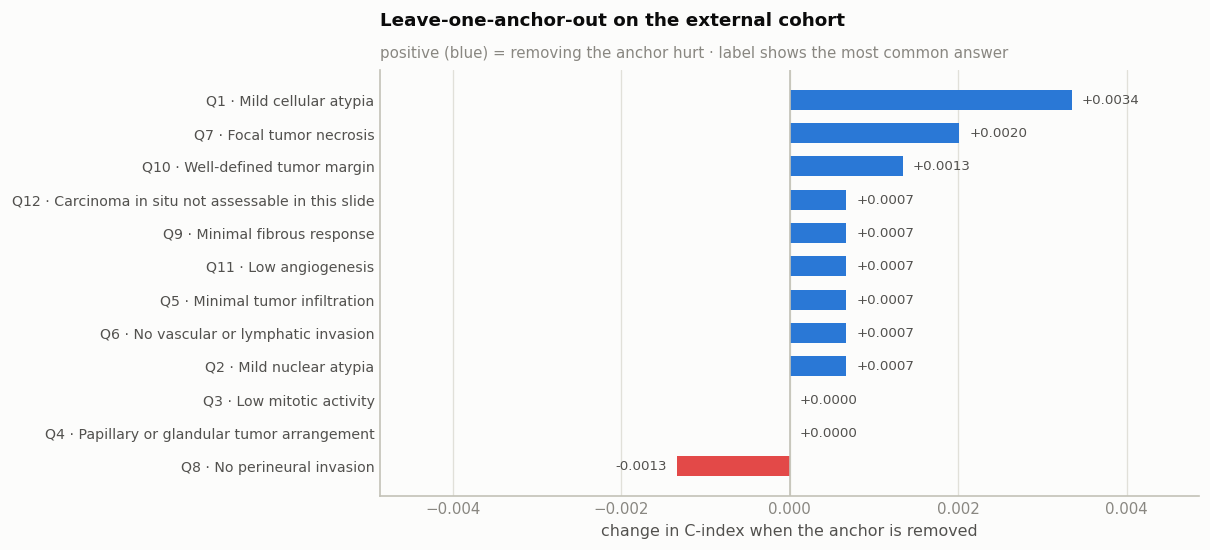

In [14]:
anchors_df = pd.read_csv(ANCHOR_CSV, engine="python")
q_cols = sorted([c for c in anchors_df.columns if c.startswith("Q") and c[1:].isdigit()],
                key=lambda c: int(c[1:]))[:cfg.num_questions]
modal_answer = {q: anchors_df[q].mode().iat[0] for q in q_cols}

trained = model
base_c = metrics["c_index"]

@torch.no_grad()
def c_index_dropping(q_idx):
    """Re-evaluate with anchor ``q_idx`` removed from every case."""
    trained.eval()
    trained.num_questions -= 1
    try:
        risks, cens, times = [], [], []
        for batch in loaders["test"]:
            x_text = batch["text"].to(DEVICE)
            keep = [q for q in range(x_text.shape[1]) if q != q_idx]
            o = trained.forward_no_loss(batch["img"].to(DEVICE), x_text[:, keep])
            alpha = o["evidence"] + 1.0
            p = alpha / alpha.sum(dim=1, keepdim=True)
            s = torch.flip(torch.cumsum(torch.flip(p, dims=[1]), dim=1), dims=[1]) - p
            risks.append((-s.sum(dim=1)).cpu().numpy())
            cens.append(batch["censorship"].numpy().ravel())
            times.append(batch["survival_time"].numpy().ravel())
        return c_index(np.concatenate(risks), np.concatenate(cens), np.concatenate(times))
    finally:
        trained.num_questions += 1

deltas = np.array([base_c - c_index_dropping(q) for q in range(cfg.num_questions)])
order = np.argsort(deltas)
labels = [f"{q_cols[i]} · {str(modal_answer[q_cols[i]])[:46]}" for i in order]

fig, ax = plt.subplots(figsize=(8.8, 4.6))
colors = [DIVERGING["low"] if d > 0 else DIVERGING["high"] for d in deltas[order]]
ax.barh(np.arange(len(order)), deltas[order], color=colors, height=0.6)
ax.axvline(0, color=BASELINE, linewidth=1.0)
ax.set_yticks(np.arange(len(order)), labels, fontsize=8.5, color=INK_2)
lim = max(np.abs(deltas).max(), 1e-6) * 1.45
for y, d in enumerate(deltas[order]):
    ax.text(d + (1 if d >= 0 else -1) * lim * 0.025, y, f"{d:+.4f}", va="center", fontsize=8,
            ha="left" if d >= 0 else "right", color=INK_2)
ax.set_xlim(-lim, lim)
style_axes(ax, "Leave-one-anchor-out on the external cohort",
           "change in C-index when the anchor is removed", "",
           subtitle="positive (blue) = removing the anchor hurt · label shows the most common answer",
           grid_axis="x")
save(fig, "07_anchor_importance"); plt.show()

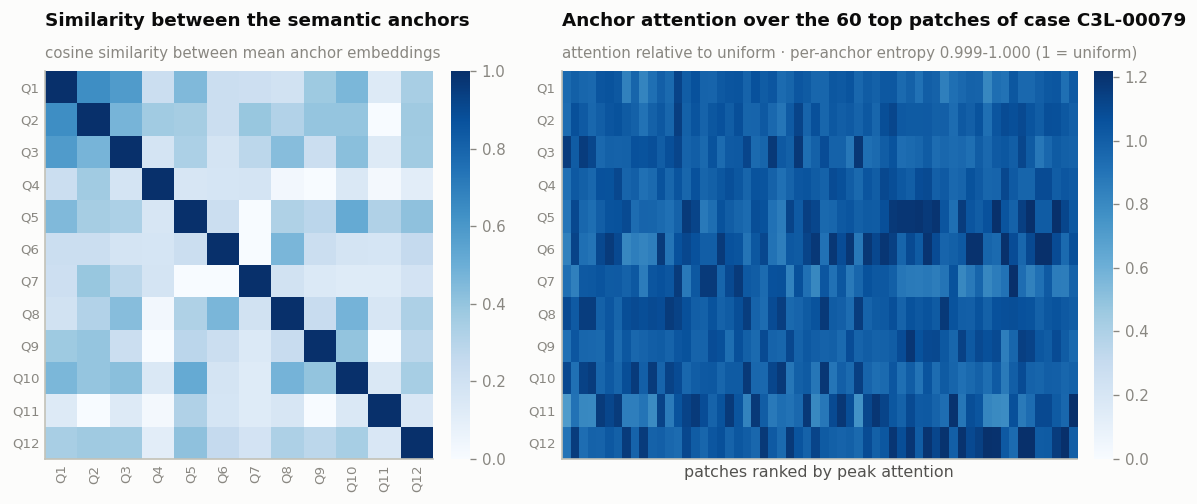

In [15]:
# how similar are the anchors to each other, and how focused is each one?
anchor_emb = np.stack([np.asarray(a) for a in datasets["test"].anchors["anchor_emb"]])  # (n, Q, D)
mean_anchor = anchor_emb.mean(axis=0)
mean_anchor /= np.linalg.norm(mean_anchor, axis=-1, keepdims=True)
sim = mean_anchor @ mean_anchor.T

# attention of every anchor over the patches of the highest-risk case
worst = int(np.argmax(risk))
with torch.no_grad():
    item = datasets["test"][worst]
    o = trained.forward_no_loss(item["img"][None].to(DEVICE), item["text"][None].to(DEVICE))
A = o["A_coattn"][0].cpu().numpy()                                   # (Q, n_patches)
entropy = -(A * np.log(A + 1e-12)).sum(axis=1) / np.log(A.shape[1])  # 1 = uniform, 0 = one patch

fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.3),
                         gridspec_kw={"width_ratios": [1.05, 1]})

im = axes[0].imshow(sim, cmap="Blues", vmin=0, vmax=1)
axes[0].set_xticks(range(len(q_cols)), q_cols, fontsize=8, rotation=90)
axes[0].set_yticks(range(len(q_cols)), q_cols, fontsize=8)
style_axes(axes[0], "Similarity between the semantic anchors", "", "",
           subtitle="cosine similarity between mean anchor embeddings", grid_axis=None)
fig.colorbar(im, ax=axes[0], fraction=0.045, pad=0.03).outline.set_visible(False)

# show attention relative to uniform (1.0 = uniform over all N patches)
top = np.argsort(A.max(axis=0))[-60:]
rel = A[:, top] * A.shape[1]
im2 = axes[1].imshow(rel, aspect="auto", cmap="Blues", vmin=0, vmax=np.percentile(rel, 99))
axes[1].set_yticks(range(len(q_cols)), q_cols, fontsize=8)
axes[1].set_xticks([])
style_axes(axes[1], f"Anchor attention over the 60 top patches of case {dumps['case_ids'][worst]}",
           "patches ranked by peak attention", "",
           subtitle="attention relative to uniform · per-anchor entropy " +
                    f"{entropy.min():.3f}-{entropy.max():.3f} (1 = uniform)", grid_axis=None)
fig.colorbar(im2, ax=axes[1], fraction=0.045, pad=0.03).outline.set_visible(False)
fig.tight_layout()
save(fig, "08_anchors"); plt.show()

## 9 · Summary

Every figure above is written to `RESULTS_DIR/figures/`. The per-case risk
scores, predicted survival curves and evidential diagnostics are in `dumps`, and
the cell below saves them next to the figures.

In [16]:
print(f"reported   C-index : {REPORTED['c_index']:.4f}")
print(f"reproduced C-index : {metrics['c_index']:.4f}   "
      f"({abs(metrics['c_index'] - REPORTED['c_index']) / REPORTED['c_index']:.2%} relative)")
print(f"\ntraining setting behind these weights:\n  {REPORTED_SETTING}")
pd.DataFrame({k: v for k, v in dumps.items() if getattr(v, "ndim", 0) == 1}).to_csv(
    RESULTS_DIR / "predictions_test.csv", index=False)

print(f"\nartefacts in {RESULTS_DIR.resolve()}")
for f in sorted(RESULTS_DIR.rglob("*")):
    if f.is_file():
        print(f"  {f.relative_to(RESULTS_DIR)}")

reported   C-index : 0.6770
reproduced C-index : 0.6769   (0.01% relative)

training setting behind these weights:
  alpha = 0.5, r = 1.0, tau = 1.0, lr = 1e-4, 30 epochs, AdamW, wd 1e-5, cosine, no warmup

artefacts in /hpc/home/e0950223/SAEFS/results/kirc_reproduction
  figures/01_cohorts.png
  figures/02_reproduction.png
  figures/03_risk_stratification.png
  figures/04_calibration.png
  figures/05_uncertainty.png
  figures/06_retention.png
  figures/07_anchor_importance.png
  figures/08_anchors.png
  predictions_test.csv
